Imports:

In [108]:
import librosa
import numpy as np
import matplotlib.pyplot as plt

Import audio file(s):

In [109]:
MAX_DURATION = 4.0

audio_signal, sample_rate = librosa.load(
    "instrument_set/keys/keys.wav",
    duration=MAX_DURATION
    )


22050


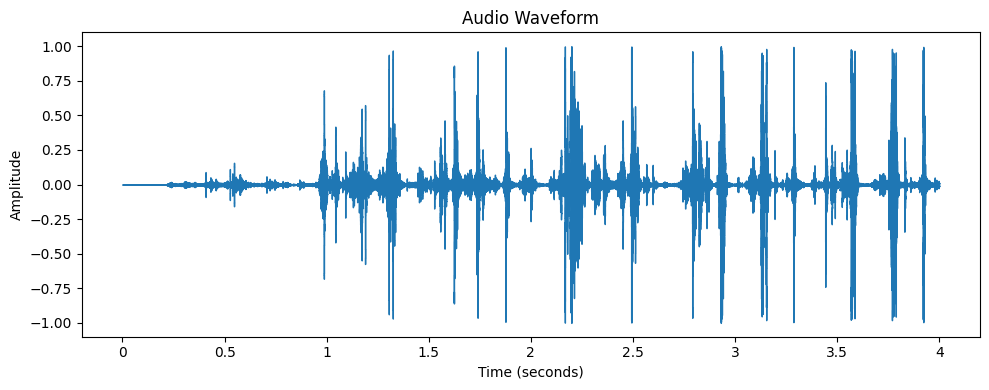

In [110]:
print(sample_rate)

# Display waveform
plt.figure(figsize=(10, 4))

librosa.display.waveshow(
    audio_signal,
    sr=sample_rate
)

plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

Creating spectrograms:

In [111]:
N_MELS = 128

# Creat Mel spectogram
mel_spectogram = librosa.feature.melspectrogram(
    y = audio_signal,
    sr = sample_rate,
    n_mels = N_MELS,
    fmax=8000
)
# Convert power values to decibels (log scale)
mel_spectogram_db = librosa.power_to_db(
    mel_spectogram,
    ref=np.max
)


# Linear spectogram
stft = librosa.stft(audio_signal, n_fft=2048, hop_length=512)
linear_spectrogram_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)

# librosa.display.specshow(
#     spectrogram_db,
#     sr=sample_rate,
#     x_axis="time",
#     y_axis="hz"
# )

In [113]:
# 4. Create extent arrays for proper axes (x=time, y=freq)
time_mel = np.linspace(0, 5.0, mel_spectogram_db.shape[1])
freq_mel = np.linspace(0, 8000, mel_spectogram_db.shape[0])

time_linear = np.linspace(0, 5.0, linear_spectrogram_db.shape[1])
freq_linear = np.linspace(0, 8000, linear_spectrogram_db.shape[0])

Display Spectrogram

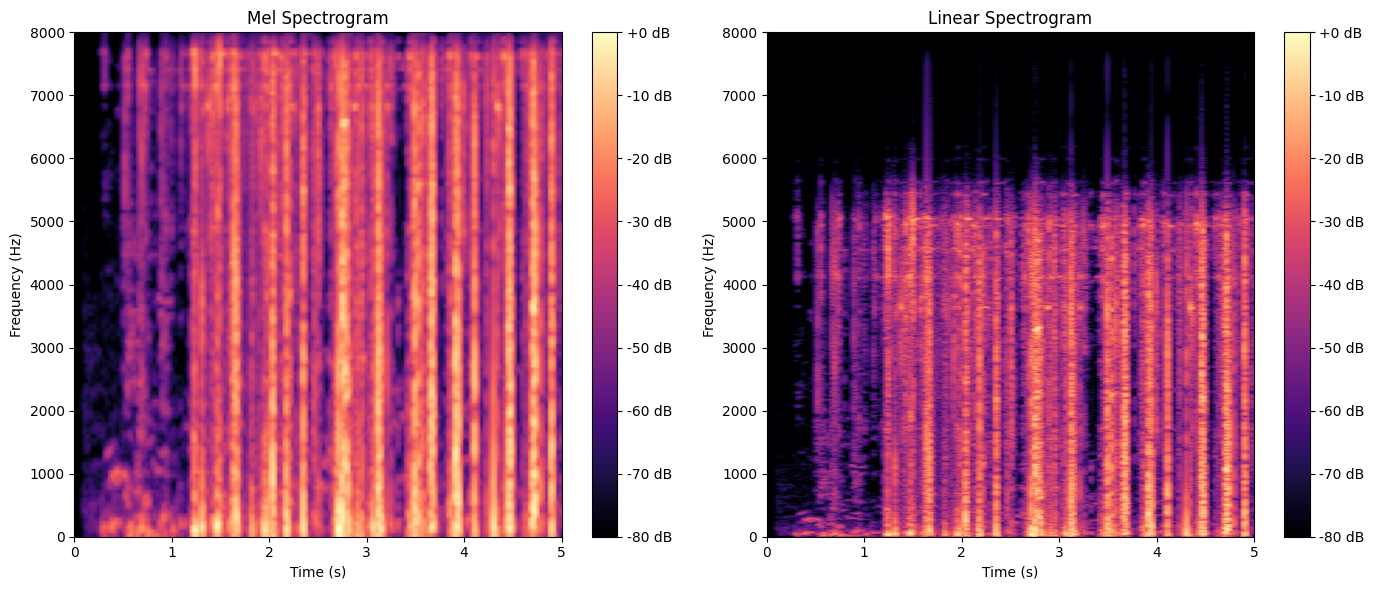

In [114]:
# 5. Plot side-by-side using imshow
fig, axes = plt.subplots(1,2, figsize=(14,6))

# Mel spectrogram
im1 = axes[0].imshow(
    mel_spectogram_db,
    origin='lower',
    aspect='auto',
    extent=[time_mel[0], time_mel[-1], freq_mel[0], freq_mel[-1]],
    cmap='magma'
)
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Frequency (Hz)')
axes[0].set_title('Mel Spectrogram')
fig.colorbar(im1, ax=axes[0], format="%+2.0f dB")

# Linear spectrogram
im2 = axes[1].imshow(
    linear_spectrogram_db,
    origin='lower',
    aspect='auto',
    extent=[time_linear[0], time_linear[-1], freq_linear[0], freq_linear[-1]],
    cmap='magma'
)
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Frequency (Hz)')
axes[1].set_title('Linear Spectrogram')
fig.colorbar(im2, ax=axes[1], format="%+2.0f dB")

# 6. Force same limits for apples-to-apples comparison
axes[0].set_xlim(0,5)
axes[1].set_xlim(0,5)
axes[0].set_ylim(0,8000)
axes[1].set_ylim(0,8000)

plt.tight_layout()
plt.show()